<a href="https://colab.research.google.com/github/Lul-del/BAE-Russian-beauty-salon/blob/main/Copy_of_Entrainement_model_fongbe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers datasets accelerate evaluate jiwer librosa soundfile

from datasets import load_dataset, Audio
ds = load_dataset("Professor/fongbe-speech-zenodo")
print(ds)
print(ds["train"].features)   # repérez la colonne texte

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 47.3 MB/s eta 0:00:00


README.md:   0%|          | 0.00/4.79k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  304MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  322MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

... (6 outputs left out)

Generating train split:   0%|          | 0/8234 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3179 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2168 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['audio', 'text', 'speaker ID', 'audio filename'],
        num_rows: 8234
    })
    validation: Dataset({
        features: ['audio', 'text', 'speaker ID', 'audio filename'],
        num_rows: 3179
    })
    test: Dataset({
        features: ['audio', 'text', 'speaker ID', 'audio filename'],
        num_rows: 2168
    })
})
{'audio': Audio(sampling_rate=16000, decode=True, num_channels=None, stream_index=None), 'text': Value('string'), 'speaker ID': Value('string'), 'audio filename': Value('string')}


### CELLULE 2 - Chargement, Nettoyage et Construction du Vocabulaire (MMS)

In [ ]:
import re
import json
import unicodedata
from datasets import load_dataset, Audio

# Paramètres du cahier des charges
TONES = False     # Premier essai sans tons pour simplifier le dictionnaire
COL = "text"

# 1. Chargement du dataset et forçage de la fréquence à 16kHz
print("Chargement du dataset...")
ds = load_dataset("Professor/fongbe-speech-zenodo")
ds = ds.cast_column("audio", Audio(sampling_rate=16_000))

# 2. Table de mapping pour unifier les caractères spécifiques du Fongbe
MAP = {"ε": "ɛ", "ɑ": "a", "ɩ": "i", "\u0306": "\u030c"}

def est_marque(c):
    # Détecte si le caractère est un accent combinant (ton)
    return unicodedata.category(c).startswith("M")

def nettoyer(b):
    # Normalisation Décomposée pour séparer les lettres et leurs accents
    t = unicodedata.normalize("NFD", b[COL]).lower()

    # Unification des lettres
    t = "".join(MAP.get(c, c) for c in t)

    # Retrait des tons si configuré ainsi
    if not TONES:
        t = "".join(c for c in t if not est_marque(c))

    # Conservation uniquement de l'alphanumérique, de l'espace et de l'apostrophe
    t = "".join(c if (c.isalnum() or c in " '" or est_marque(c)) else " " for c in t)

    # Normalisation Recomposée
    t = unicodedata.normalize("NFC", t)

    # Suppression des espaces multiples
    b[COL] = re.sub(r"\s+", " ", t).strip()
    return b

# Application du nettoyage
print("Nettoyage du dataset en cours...")
ds = ds.map(nettoyer)

# 3. Extraction du vocabulaire unique sur l'ensemble des splits
chars = set()
for split in ds:
    for t in ds[split][COL]:
        chars.update(t)

# Construction du fichier vocab.json requis pour le tokenizer
vocab = {c: i for i, c in enumerate(sorted(chars))}
vocab["|"] = vocab.pop(" ")
vocab["[UNK]"] = len(vocab)
vocab["[PAD]"] = len(vocab)

print(f"\nVocabulaire généré ({len(vocab)} caractères) :")
print(sorted(vocab))


Chargement du dataset...
Nettoyage du dataset en cours...

Vocabulaire généré (33 caractères) :
['0', '2', '[PAD]', '[UNK]', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '|', 'ɔ', 'ɖ', 'ɛ']


### CELLULE 3 - Processeur et Modèle MMS (Meta)

In [ ]:
import json
from transformers import (
    Wav2Vec2CTCTokenizer,
    Wav2Vec2FeatureExtractor,
    Wav2Vec2Processor,
    Wav2Vec2ForCTC
)

# 1. Sauvegarde du vocabulaire et configuration du Tokenizer
json.dump(vocab, open("vocab.json", "w"), ensure_ascii=False)
tokenizer = Wav2Vec2CTCTokenizer(
    "vocab.json",
    unk_token="[UNK]",
    pad_token="[PAD]",
    word_delimiter_token="|"
)

# 2. Extracteur de caractéristiques audio (16kHz)
fe = Wav2Vec2FeatureExtractor(
    feature_size=1,
    sampling_rate=16000,
    padding_value=0.0,
    do_normalize=True,
    return_attention_mask=True
)

# 3. Assemblage du processeur
processor = Wav2Vec2Processor(feature_extractor=fe, tokenizer=tokenizer)

# 4. Fonction de préparation dynamique (évite de saturer la RAM)
def prep(batch):
    arrays = [a["array"] for a in batch["audio"]]
    out = processor(arrays, sampling_rate=16000)
    return {
        "input_values": out.input_values,
        "labels": processor(text=batch[COL]).input_ids
    }

# Transformation à la volée
train_ds = ds["train"].with_transform(prep)
val_ds   = ds["validation"].with_transform(prep)
test_ds  = ds["test"].with_transform(prep)

# 5. Chargement de facebook/mms-1b-all avec initialisation des adapters
print("Chargement du modèle facebook/mms-1b-all...")
model = Wav2Vec2ForCTC.from_pretrained(
    "facebook/mms-1b-all",
    attention_dropout=0.0,
    hidden_dropout=0.0,
    feat_proj_dropout=0.0,
    layerdrop=0.0,
    ctc_loss_reduction="mean",
    pad_token_id=processor.tokenizer.pad_token_id,
    vocab_size=len(processor.tokenizer),
    ignore_mismatched_sizes=True
)

# Activation et isolement des adapters (Fine-Tuning léger)
model.init_adapter_layers()
model.freeze_base_model()
for p in model._get_adapters().values():
    p.requires_grad = True

print("Modèle et processeur MMS configurés avec succès !")
print(f"Paramètres entraînables : {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Chargement du modèle facebook/mms-1b-all...


Loading weights:   0%|          | 0/1096 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/mms-1b-all
Key            | Status   |                                                                                            
---------------+----------+--------------------------------------------------------------------------------------------
lm_head.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([154, 1280]) vs model:torch.Size([35, 1280])
lm_head.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([154]) vs model:torch.Size([35])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Modèle et processeur MMS configurés avec succès !
Paramètres entraînables : 2,196,003


### CELLULE 4 - Entraînement de l'Adapter MMS

In [ ]:
!pip install -q evaluate jiwer

import gc
import os
import torch
import numpy as np
import evaluate
from dataclasses import dataclass
from transformers import TrainingArguments, Trainer
from google.colab import drive

# Libérer la mémoire GPU saturée par les précédentes exécutions (Whisper, etc.)
gc.collect()
torch.cuda.empty_cache()
print("Mémoire GPU nettoyée.")

# 1. Montage optionnel de Google Drive
save_dir = "./mms-fon"
print("Tentative de montage de Google Drive...")
try:
    drive.mount("/content/drive", force_remount=True)
    save_dir = "/content/drive/MyDrive/mms-fon"
    print("=> Google Drive monté avec succès. Les sauvegardes seront persistantes.")
except Exception as e:
    print(f"=> Échec du montage ({type(e).__name__}). Sauvegarde locale temporaire activée : {save_dir}")

# 2. Collator pour le padding dynamique
@dataclass
class Collator:
    processor: Wav2Vec2Processor
    def __call__(self, feats):
        inp = [{"input_values": f["input_values"]} for f in feats]
        lab = [{"input_ids": f["labels"]} for f in feats]

        batch = self.processor.pad(inp, padding=True, return_tensors="pt")
        lb = self.processor.pad(labels=lab, padding=True, return_tensors="pt")

        batch["labels"] = lb["input_ids"].masked_fill(lb.attention_mask.ne(1), -100)
        return batch

# 3. Métrique d'évaluation Word Error Rate (WER)
wer = evaluate.load("wer")

def metrics(pred):
    ids = np.argmax(pred.predictions, axis=-1)
    pred.label_ids[pred.label_ids == -100] = processor.tokenizer.pad_token_id
    p = processor.batch_decode(ids)
    r = processor.batch_decode(pred.label_ids, group_tokens=False)
    return {"wer": wer.compute(predictions=p, references=r)}

# 4. Arguments d'entraînement optimisés pour éviter le CUDA Out-Of-Memory
args = TrainingArguments(
    output_dir=save_dir,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=1e-3,
    num_train_epochs=1,
    fp16=True,
    gradient_checkpointing=True,
    remove_unused_columns=False,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    logging_steps=25,
    report_to="none"
)

# 5. Initialisation du Trainer
trainer = Trainer(
    model=model,
    args=args,
    data_collator=Collator(processor),
    compute_metrics=metrics,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=processor.feature_extractor
)

print("Lancement de l'entraînement...")
trainer.train()

Mémoire GPU nettoyée.
Tentative de montage de Google Drive...
Mounted at /content/drive
=> Google Drive monté avec succès. Les sauvegardes seront persistantes.
Lancement de l'entraînement...


Epoch,Training Loss,Validation Loss


OutOfMemoryError: CUDA out of memory. Tried to allocate 2.51 GiB. GPU 0 has a total capacity of 14.56 GiB of which 1.54 GiB is free. Including non-PyTorch memory, this process has 13.02 GiB memory in use. Of the allocated memory 12.48 GiB is allocated by PyTorch, and 404.19 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
# Arrêt et redémarrage automatique du Runtime pour vider 100% de la RAM et du GPU
import os
from google.colab import runtime

print("Redémarrage du runtime en cours pour vider la mémoire...")
runtime.unassign()

Redémarrage du runtime en cours pour vider la mémoire...


### Étape 1 : Optimisation de l'allocation CUDA et chargement des dépendances

In [ ]:
import os
# Empêche la fragmentation de la VRAM
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import re
import gc
import json
import unicodedata
import torch
import numpy as np
import evaluate
from dataclasses import dataclass
from datasets import load_dataset, Audio
from transformers import (
    Wav2Vec2CTCTokenizer,
    Wav2Vec2FeatureExtractor,
    Wav2Vec2Processor,
    Wav2Vec2ForCTC,
    TrainingArguments,
    Trainer
)
from google.colab import drive

### Étape 2 : Chargement, Nettoyage du Dataset et Préparation des splits

In [ ]:
# Chargement du dataset
ds = load_dataset("Professor/fongbe-speech-zenodo")
ds = ds.cast_column("audio", Audio(sampling_rate=16_000))

# Nettoyage sans les tons pour cette phase d'alignement du vocabulaire
TONES = False
COL = "text"
MAP = {"ε": "ɛ", "ɑ": "a", "ɩ": "i", "\u0306": "\u030c"}

def est_marque(c):
    return unicodedata.category(c).startswith("M")

def nettoyer(b):
    t = unicodedata.normalize("NFD", b[COL]).lower()
    t = "".join(MAP.get(c, c) for c in t)
    if not TONES:
        t = "".join(c for c in t if not est_marque(c))
    t = "".join(c if (c.isalnum() or c in " '" or est_marque(c)) else " " for c in t)
    t = unicodedata.normalize("NFC", t)
    b[COL] = re.sub(r"\s+", " ", t).strip()
    return b

ds = ds.map(nettoyer)

# Reconstitution du dictionnaire de 33 caractères
chars = set()
for split in ds:
    for t in ds[split][COL]:
        chars.update(t)

vocab = {c: i for i, c in enumerate(sorted(chars))}
vocab["|"] = vocab.pop(" ")
vocab["[UNK]"] = len(vocab)
vocab["[PAD]"] = len(vocab)

# Sauvegarde
with open("vocab.json", "w", encoding="utf-8") as f:
    json.dump(vocab, f, ensure_ascii=False)

print(f"Vocabulaire généré avec {len(vocab)} caractères.")

Map:   0%|          | 0/8234 [00:00<?, ? examples/s]

Map:   0%|          | 0/3179 [00:00<?, ? examples/s]

Map:   0%|          | 0/2168 [00:00<?, ? examples/s]

Vocabulaire généré avec 33 caractères.


### Étape 3 : Initialisation du processeur et du modèle MMS

In [ ]:
tokenizer = Wav2Vec2CTCTokenizer(
    "vocab.json",
    unk_token="[UNK]",
    pad_token="[PAD]",
    word_delimiter_token="|"
)

fe = Wav2Vec2FeatureExtractor(
    feature_size=1,
    sampling_rate=16000,
    padding_value=0.0,
    do_normalize=True,
    return_attention_mask=True
)

processor = Wav2Vec2Processor(feature_extractor=fe, tokenizer=tokenizer)

def prep(batch):
    arrays = [a["array"] for a in batch["audio"]]
    out = processor(arrays, sampling_rate=16000)
    return {
        "input_values": out.input_values,
        "labels": processor(text=batch[COL]).input_ids
    }

# Application de la transformation dynamique
train_ds = ds["train"].with_transform(prep)
test_ds  = ds["test"].with_transform(prep)

# Sous-ensemble de validation réduit pour surveiller l'entraînement de manière sécurisée
val_small = ds["validation"].shuffle(seed=42).select(range(400)).with_transform(prep)

# Chargement du modèle MMS de base
model = Wav2Vec2ForCTC.from_pretrained(
    "facebook/mms-1b-all",
    attention_dropout=0.0,
    hidden_dropout=0.0,
    feat_proj_dropout=0.0,
    layerdrop=0.0,
    ctc_loss_reduction="mean",
    pad_token_id=processor.tokenizer.pad_token_id,
    vocab_size=len(processor.tokenizer),
    ignore_mismatched_sizes=True
)

model.init_adapter_layers()
model.freeze_base_model()
for p in model._get_adapters().values():
    p.requires_grad = True

print("Modèle et processeur MMS prêts à l'entraînement !")

Loading weights:   0%|          | 0/1096 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/mms-1b-all
Key            | Status   |                                                                                            
---------------+----------+--------------------------------------------------------------------------------------------
lm_head.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([154, 1280]) vs model:torch.Size([35, 1280])
lm_head.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([154]) vs model:torch.Size([35])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Modèle et processeur MMS prêts à l'entraînement !


### Étape 4 : Configuration sécurisée de l'entraînement et exécution

In [ ]:
gc.collect()
torch.cuda.empty_cache()

save_dir = "./mms-fon"
try:
    drive.mount("/content/drive", force_remount=True)
    save_dir = "/content/drive/MyDrive/mms-fon"
    print("=> Google Drive disponible.")
except Exception as e:
    print(f"=> Sauvegarde locale temporaire activée.")

@dataclass
class Collator:
    processor: Wav2Vec2Processor
    def __call__(self, feats):
        inp = [{"input_values": f["input_values"]} for f in feats]
        lab = [{"input_ids": f["labels"]} for f in feats]
        batch = self.processor.pad(inp, padding=True, return_tensors="pt")
        lb = self.processor.pad(labels=lab, padding=True, return_tensors="pt")
        batch["labels"] = lb["input_ids"].masked_fill(lb.attention_mask.ne(1), -100)
        return batch

wer = evaluate.load("wer")
def metrics(pred):
    ids = np.argmax(pred.predictions, axis=-1)
    pred.label_ids[pred.label_ids == -100] = processor.tokenizer.pad_token_id
    p = processor.batch_decode(ids)
    r = processor.batch_decode(pred.label_ids, group_tokens=False)
    return {"wer": wer.compute(predictions=p, references=r)}

# Arguments corrigés pour éviter les OOM de validation
args = TrainingArguments(
    output_dir=save_dir,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    per_device_eval_batch_size=1,        # Sécurité maximale contre les fichiers très longs
    eval_accumulation_steps=20,
    learning_rate=1e-3,
    num_train_epochs=1,                  # 1 époque pour valider la stabilité du pipeline
    fp16=True,
    gradient_checkpointing=True,
    remove_unused_columns=False,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    logging_steps=25,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    data_collator=Collator(processor),
    compute_metrics=metrics,
    train_dataset=train_ds,
    eval_dataset=val_small,
    processing_class=processor.feature_extractor
)

print("Démarrage de l'entraînement...")
trainer.train()

Mounted at /content/drive
=> Google Drive disponible.
Démarrage de l'entraînement...


Epoch,Training Loss,Validation Loss,Wer
1,7.489052,1.571699,0.685738


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=515, training_loss=11.365885880849893, metrics={'train_runtime': 1351.6323, 'train_samples_per_second': 6.092, 'train_steps_per_second': 0.381, 'total_flos': 2.6689513523598607e+18, 'train_loss': 11.365885880849893, 'epoch': 1.0})

### CELLULE 5 - Sauvegarde de l'Adapter MMS

In [ ]:
import os
from safetensors.torch import save_file
from transformers.models.wav2vec2.modeling_wav2vec2 import WAV2VEC2_ADAPTER_SAFE_FILE

# Définition du répertoire de sauvegarde finale
dossier_sauvegarde = "/content/drive/MyDrive/adapter-fon"
os.makedirs(dossier_sauvegarde, exist_ok=True)

print("Sauvegarde finale des adapters de l'appareil...")
# 1. Sauvegarde des poids de l'adapter MMS spécifique au Fongbe
save_file(
    model._get_adapters(),
    os.path.join(dossier_sauvegarde, WAV2VEC2_ADAPTER_SAFE_FILE.format("fon")),
    metadata={"format": "pt"}
)

# 2. Sauvegarde du processeur de jetons
processor.save_pretrained(dossier_sauvegarde)

print(f"Sauvegarde terminée avec succès sur votre Drive dans : {dossier_sauvegarde}")

Sauvegarde finale des adapters de l'appareil...


NameError: name 'model' is not defined

### CELLULE 6 - Évaluation Finale

In [ ]:
# Évaluation finale sur l'ensemble de test en utilisant le lot de taille 1 pour éviter tout OOM
print("Lancement de l'évaluation finale sur le jeu de test...")
resultat_evaluation = trainer.evaluate(test_ds)

print("\n--- RÉSULTATS DE L'ÉVALUATION FINALE ---")
for k, v in resultat_evaluation.items():
    print(f"{k} : {v}")

Lancement de l'évaluation finale sur le jeu de test...


NameError: name 'trainer' is not defined

In [ ]:
import os
import re
import json
import unicodedata
import torch
from datasets import load_dataset
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor, Wav2Vec2CTCTokenizer, Wav2Vec2FeatureExtractor
from safetensors.torch import save_file
from transformers.models.wav2vec2.modeling_wav2vec2 import WAV2VEC2_ADAPTER_SAFE_FILE
from google.colab import drive

# 1. Montage de Google Drive pour récupérer le checkpoint
try:
    print("Connexion à Google Drive...")
    drive.mount("/content/drive", force_remount=True)
    dossier_checkpoint = "/content/drive/MyDrive/mms-fon"
    print("=> Google Drive monté avec succès !")
except Exception as e:
    print(f"Erreur d'accès à Google Drive : {e}")
    dossier_checkpoint = "./mms-fon"

# 2. Reconstitution automatique de vocab.json si manquant
if not os.path.exists("vocab.json"):
    print("Reconstitution du vocabulaire 'vocab.json' depuis le dataset...")
    ds = load_dataset("Professor/fongbe-speech-zenodo")
    MAP = {"ε": "ɛ", "ɑ": "a", "ɩ": "i", "\u0306": "\u030c"}
    def est_marque(c):
        return unicodedata.category(c).startswith("M")
    def nettoyer(b):
        t = unicodedata.normalize("NFD", b["text"]).lower()
        t = "".join(MAP.get(c, c) for c in t)
        t = "".join(c for c in t if not est_marque(c))
        t = "".join(c if (c.isalnum() or c in " '" or est_marque(c)) else " " for c in t)
        b["text"] = re.sub(r"\s+", " ", unicodedata.normalize("NFC", t)).strip()
        return b
    ds = ds.map(nettoyer)
    chars = set()
    for split in ds:
        for t in ds[split]["text"]:
            chars.update(t)
    vocab = {c: i for i, c in enumerate(sorted(chars))}
    vocab["|"] = vocab.pop(" ")
    vocab["[UNK]"] = len(vocab)
    vocab["[PAD]"] = len(vocab)
    with open("vocab.json", "w", encoding="utf-8") as f:
        json.dump(vocab, f, ensure_ascii=False)
    print("Fichier vocab.json régénéré !")

# 3. Initialisation du processeur
tokenizer = Wav2Vec2CTCTokenizer("vocab.json", unk_token="[UNK]", pad_token="[PAD]", word_delimiter_token="|")
fe = Wav2Vec2FeatureExtractor(feature_size=1, sampling_rate=16000, padding_value=0.0, do_normalize=True, return_attention_mask=True)
processor = Wav2Vec2Processor(feature_extractor=fe, tokenizer=tokenizer)

# 4. Chargement du modèle depuis le dernier checkpoint sauvegardé
checkpoints = [os.path.join(dossier_checkpoint, d) for d in os.listdir(dossier_checkpoint) if d.startswith("checkpoint-")] if os.path.exists(dossier_checkpoint) else []
if checkpoints:
    checkpoint_path = sorted(checkpoints, key=os.path.getmtime)[-1]
    print(f"Chargement des poids du modèle depuis : {checkpoint_path}")
    model = Wav2Vec2ForCTC.from_pretrained(
        checkpoint_path,
        pad_token_id=processor.tokenizer.pad_token_id,
        vocab_size=len(processor.tokenizer),
        ignore_mismatched_sizes=True
    )
else:
    print("Aucun checkpoint trouvé sur Google Drive. Chargement du modèle de base...")
    model = Wav2Vec2ForCTC.from_pretrained(
        "facebook/mms-1b-all",
        pad_token_id=processor.tokenizer.pad_token_id,
        vocab_size=len(processor.tokenizer),
        ignore_mismatched_sizes=True
    )
    model.init_adapter_layers()

# 5. Sauvegarde finale de l'adapter propre
dossier_sauvegarde = "/content/drive/MyDrive/adapter-fon"
os.makedirs(dossier_sauvegarde, exist_ok=True)

save_file(
    model._get_adapters(),
    os.path.join(dossier_sauvegarde, WAV2VEC2_ADAPTER_SAFE_FILE.format("fon")),
    metadata={"format": "pt"}
)
processor.save_pretrained(dossier_sauvegarde)
print(f"\n=> Sauvegarde finale de l'adapter validée dans : {dossier_sauvegarde}")

Connexion à Google Drive...
Mounted at /content/drive
=> Google Drive monté avec succès !
Reconstitution du vocabulaire 'vocab.json' depuis le dataset...


README.md:   0%|          | 0.00/4.79k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  304MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  322MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

... (11 outputs left out)

Map:   0%|          | 0/2168 [00:00<?, ? examples/s]

Fichier vocab.json régénéré !
Chargement des poids du modèle depuis : /content/drive/MyDrive/mms-fon/checkpoint-515


Loading weights:   0%|          | 0/1096 [00:00<?, ?it/s]


=> Sauvegarde finale de l'adapter validée dans : /content/drive/MyDrive/adapter-fon


In [ ]:
!pip install -q evaluate jiwer

import gc
import re
import torch
import evaluate
import numpy as np
import unicodedata
from dataclasses import dataclass
from datasets import load_dataset, Audio
from transformers import Wav2Vec2Processor, Trainer, TrainingArguments

# 1. Nettoyage de la mémoire GPU
gc.collect()
torch.cuda.empty_cache()
print("Mémoire GPU nettoyée.")

# 2. Rechargement et préparation dynamique de test_ds
print("Chargement et nettoyage du jeu de test (test_ds)...")
ds = load_dataset("Professor/fongbe-speech-zenodo")
ds = ds.cast_column("audio", Audio(sampling_rate=16_000))

MAP = {"ε": "ɛ", "ɑ": "a", "ɩ": "i", "\u0306": "\u030c"}
def est_marque(c):
    return unicodedata.category(c).startswith("M")

def nettoyer(b):
    t = unicodedata.normalize("NFD", b["text"]).lower()
    t = "".join(MAP.get(c, c) for c in t)
    t = "".join(c for c in t if not est_marque(c))
    t = "".join(c if (c.isalnum() or c in " '" or est_marque(c)) else " " for c in t)
    b["text"] = re.sub(r"\s+", " ", unicodedata.normalize("NFC", t)).strip()
    return b

ds = ds.map(nettoyer)

def prep(batch):
    arrays = [a["array"] for a in batch["audio"]]
    out = processor(arrays, sampling_rate=16000)
    return {
        "input_values": out.input_values,
        "labels": processor(text=batch["text"]).input_ids
    }

test_ds = ds["test"].with_transform(prep)

# 3. Préparation du Collator
@dataclass
class Collator:
    processor: Wav2Vec2Processor
    def __call__(self, feats):
        inp = [{"input_values": f["input_values"]} for f in feats]
        lab = [{"input_ids": f["labels"]} for f in feats]
        batch = self.processor.pad(inp, padding=True, return_tensors="pt")
        lb = self.processor.pad(labels=lab, padding=True, return_tensors="pt")
        batch["labels"] = lb["input_ids"].masked_fill(lb.attention_mask.ne(1), -100)
        return batch

# 4. Métrique d'évaluation Word Error Rate (WER)
wer = evaluate.load("wer")
def metrics(pred):
    ids = np.argmax(pred.predictions, axis=-1)
    pred.label_ids[pred.label_ids == -100] = processor.tokenizer.pad_token_id
    p = processor.batch_decode(ids)
    r = processor.batch_decode(pred.label_ids, group_tokens=False)
    return {"wer": wer.compute(predictions=p, references=r)}

# 5. Arguments d'évaluation sécurisés
eval_args = TrainingArguments(
    output_dir="./mms-eval",
    per_device_eval_batch_size=1,
    eval_accumulation_steps=20,
    remove_unused_columns=False,
    fp16=True,
    report_to="none"
)

# 6. Création du Trainer pour évaluation uniquement
trainer_eval = Trainer(
    model=model,
    args=eval_args,
    data_collator=Collator(processor),
    compute_metrics=metrics,
    eval_dataset=test_ds,
    processing_class=processor.feature_extractor
)

# 7. Lancement de l'évaluation
print("Lancement de l'évaluation finale sur le jeu de test...")
resultats = trainer_eval.evaluate()

print("\n--- RÉSULTATS DE L'ÉVALUATION FINALE (MMS) ---")
for k, v in resultats.items():
    print(f"{k} : {v}")

Mémoire GPU nettoyée.
Chargement et nettoyage du jeu de test (test_ds)...


Map:   0%|          | 0/8234 [00:00<?, ? examples/s]

Map:   0%|          | 0/3179 [00:00<?, ? examples/s]

Map:   0%|          | 0/2168 [00:00<?, ? examples/s]

Lancement de l'évaluation finale sur le jeu de test...


Training Loss,Validation Loss,Step,Wer
No log,2.260142,0,0.654731



--- RÉSULTATS DE L'ÉVALUATION FINALE (MMS) ---
eval_loss : 2.2601420879364014
eval_wer : 0.6547310153952604


```markdown
## Étape 1 : Exploration du Dataset Fongbe
Regardons les caractéristiques d'un exemple pour identifier les colonnes contenant l'audio et la transcription textuelle.
```

In [ ]:
from datasets import load_dataset

# Chargement automatique du dataset si non présent dans la session
if 'ds' not in globals():
    print("Chargement du dataset en cours...")
    ds = load_dataset("Professor/fongbe-speech-zenodo")

# Affichage d'un exemple pour inspecter les clés et les formats
exemple = ds['train'][0]
print("Exemple complet :", exemple)
print("\nStructure de l'audio :", exemple['audio'])

Chargement du dataset en cours...


README.md:   0%|          | 0.00/4.79k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  304MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  322MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

... (6 outputs left out)

Generating train split:   0%|          | 0/8234 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3179 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2168 [00:00<?, ? examples/s]

Exemple complet : {'audio': <datasets.features._torchcodec.AudioDecoder object at 0x79b75d8f8590>, 'text': 'xo ɔ gbla to nu mi', 'speaker ID': 'armandine', 'audio filename': 'armandine_fongbe_corp005_001.wav'}

Structure de l'audio : <datasets.features._torchcodec.AudioDecoder object at 0x79b75d8f8590>


```markdown
## Étape 2 : Écouter un extrait et vérifier la fréquence d'échantillonnage
Whisper nécessite généralement une fréquence d'échantillonnage de **16 000 Hz** (16kHz). Nous allons caster la colonne audio et jouer un échantillon.
```

In [ ]:
from IPython.display import Audio as IPythonAudio
from datasets import load_dataset, Audio

# Chargement automatique du dataset si non présent dans la session
if 'ds' not in globals():
    print("Chargement du dataset en cours...")
    ds = load_dataset("Professor/fongbe-speech-zenodo")

# Forcer l'échantillonnage à 16 000 Hz pour Whisper
ds = ds.cast_column("audio", Audio(sampling_rate=16_000))

# Sélectionner un exemple
exemple_16k = ds['train'][0]

print("Texte :", exemple_16k.get('transcription') or exemple_16k.get('text'))
IPythonAudio(exemple_16k['audio']['array'], rate=exemple_16k['audio']['sampling_rate'])

Texte : xo ɔ gbla to nu mi


```markdown
## Étape 3 : Chargement du processeur Whisper
Le processeur combine un extracteur de caractéristiques (pour l'audio) et un tokenizer (pour le texte).
```

In [ ]:
from transformers import WhisperProcessor

# Nous utilisons par exemple la version whisper-tiny ou whisper-small pour l'entraînement
model_id = "openai/whisper-tiny"
processor = WhisperProcessor.from_pretrained(model_id, language="French", task="transcribe")
print("Processeur configuré avec succès !")

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

Processeur configuré avec succès !


```markdown
## Étape 4 : Fonction de préparation du jeu de données
Nous convertissons l'audio brut en caractéristiques d'entrée (`input_features`) et le texte de transcription en identifiants de labels (`labels`).
```

In [ ]:
def prepare_dataset(batch):
    # Charger l'audio et extraire les caractéristiques
    audio = batch["audio"]
    batch["input_features"] = processor.feature_extractor(audio["array"], sampling_rate=audio["sampling_rate"]).input_features[0]

    # Tokeniser le texte cible (la colonne s'appelle 'text' dans ce dataset)
    batch["labels"] = processor.tokenizer(batch["text"]).input_ids
    return batch

# Tester la préparation sur un échantillon pour s'assurer que tout fonctionne
test_sample = prepare_dataset(ds["train"][0])
print("Longueur des caractéristiques d'entrée :", len(test_sample["input_features"]))
print("Labels tokenisés :", test_sample["labels"])

Longueur des caractéristiques d'entrée : 80
Labels tokenisés : [50258, 50265, 50359, 50363, 49050, 220, 133, 242, 290, 36138, 281, 3822, 2752, 50257]


```markdown
## Étape 5 : Définition du Data Collator pour Whisper
Ce collator permet d'ajuster dynamiquement la longueur des séquences audio et textuelles dans chaque batch.
```

In [ ]:
import torch
from dataclasses import dataclass
from typing import Any, Dict, List, Union
from transformers import WhisperProcessor

# Recréer le processeur si la session a été réinitialisée
if 'processor' not in globals():
    print("Rechargement du processeur...")
    model_id = "openai/whisper-tiny"
    processor = WhisperProcessor.from_pretrained(model_id, language="French", task="transcribe")

@dataclass
class DataCollatorSpeechSeq2SeqWithPadding:
    processor: Any

    def __call__(self, features: List[Dict[str, Union[List[int], torch.Tensor]]]) -> Dict[str, torch.Tensor]:
        input_features = [{"input_features": feature["input_features"]} for feature in features]
        batch = self.processor.feature_extractor.pad(input_features, return_tensors="pt")

        label_features = [{"input_ids": feature["labels"]} for feature in features]
        labels_batch = self.processor.tokenizer.pad(label_features, return_tensors="pt")

        labels = labels_batch["input_ids"].masked_fill(labels_batch.attention_mask.ne(1), -100)

        if (labels[:, 0] == self.processor.tokenizer.bos_token_id).all():
            labels = labels[:, 1:]

        batch["labels"] = labels
        return batch

data_collator = DataCollatorSpeechSeq2SeqWithPadding(processor=processor)
print("Data Collator configuré avec succès !")

Rechargement du processeur...


preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

Data Collator configuré avec succès !


```markdown
## Étape 6 : Chargement du modèle Whisper pré-entraîné
Nous chargeons le modèle de génération de séquence à séquence.
```

In [ ]:
from transformers import WhisperForConditionalGeneration, WhisperProcessor

# Recréer model_id et le processeur si absents
if 'model_id' not in globals():
    model_id = "openai/whisper-tiny"
if 'processor' not in globals():
    processor = WhisperProcessor.from_pretrained(model_id, language="French", task="transcribe")

model = WhisperForConditionalGeneration.from_pretrained(model_id)

# Configuration pour l'entraînement
model.config.use_cache = False
model.config.forced_decoder_ids = processor.get_decoder_prompt_ids(language="French", task="transcribe")
print("Modèle chargé et configuré !")

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.75k [00:00<?, ?B/s]

Modèle chargé et configuré !


```markdown
## Étape 7 : Préparation et transformation de tout le dataset
Nous appliquons la fonction de préparation en parallèle sur tout le dataset.
```

In [ ]:
# Assurer que ds est chargé
if 'ds' not in globals():
    from datasets import load_dataset
    ds = load_dataset("Professor/fongbe-speech-zenodo")

# Application du preprocessing sur le dataset
print("Préparation du dataset (cette étape peut prendre quelques minutes)...")
ds_prepared = ds.map(prepare_dataset, remove_columns=ds["train"].column_names, num_proc=1)
print("Dataset préparé avec succès !")

README.md:   0%|          | 0.00/4.79k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  304MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  322MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  280MB            

... (6 outputs left out)

Generating validation split:   0%|          | 0/3179 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2168 [00:00<?, ? examples/s]

Préparation du dataset (cette étape peut prendre quelques minutes)...


NameError: name 'prepare_dataset' is not defined

```markdown
## Étape 8 : Définition de la métrique d'évaluation (WER)
Nous chargeons la métrique standard `jiwer` pour calculer le taux d'erreur sur les mots (Word Error Rate).
```

In [ ]:
!pip install --upgrade --force-reinstall -q jiwer
import jiwer

def compute_metrics(pred):
    pred_ids = pred.predictions
    label_ids = pred.label_ids

    # Remplacer -100 par le token de padding de fin
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id

    # Décoder les prédictions et les labels réels
    pred_str = processor.tokenizer.batch_decode(pred_ids, skip_special_tokens=True)
    label_str = processor.tokenizer.batch_decode(label_ids, skip_special_tokens=True)

    # Calculer directement le taux d'erreur avec la bibliothèque jiwer
    wer = 100 * jiwer.wer(label_str, pred_str)

    return {"wer": wer}
print("Métrique WER configurée avec succès à l'aide de la bibliothèque native jiwer !")

Métrique WER configurée avec succès à l'aide de la bibliothèque native jiwer !


```markdown
## Étape 9 : Configuration de l'entraînement
Nous définissons les paramètres d'entraînement globaux avec `Seq2SeqTrainingArguments`.
```

In [ ]:
from transformers import Seq2SeqTrainingArguments

training_args = Seq2SeqTrainingArguments(
    output_dir="./whisper-tiny-fongbe",
    per_device_train_batch_size=8,
    gradient_accumulation_steps=2,  # Augmenter pour simuler de plus gros batchs
    learning_rate=1e-5,
    warmup_steps=50,
    max_steps=500,  # Réduire ou augmenter selon vos besoins de calcul
    gradient_checkpointing=True,
    fp16=True, # À utiliser si vous disposez d'un GPU compatible
    eval_strategy="steps",
    per_device_eval_batch_size=8,
    predict_with_generate=True,
    generation_max_length=225,
    save_steps=100,
    eval_steps=100,
    logging_steps=25,
    report_to=["tensorboard"],
    load_best_model_at_end=True,
    metric_for_best_model="wer",
    greater_is_better=False,
    push_to_hub=False,
)
print("Paramètres d'entraînement configurés !")

Paramètres d'entraînement configurés !


```markdown
## Étape 10 : Initialisation du Trainer et lancement du Fine-Tuning
Nous assemblons tous les composants précédents (modèle, arguments, jeux de données, collator de données et métrique) dans le `Seq2SeqTrainer`.
```

In [ ]:
from transformers import Seq2SeqTrainer
from datasets import load_dataset

# Assurer que ds_prepared est chargé et disponible
if 'ds_prepared' not in globals():
    print("Préparation automatique du dataset en cours...")
    if 'ds' not in globals():
        ds = load_dataset("Professor/fongbe-speech-zenodo")
    if 'prepare_dataset' not in globals():
        def prepare_dataset(batch):
            audio = batch["audio"]
            batch["input_features"] = processor.feature_extractor(audio["array"], sampling_rate=audio["sampling_rate"]).input_features[0]
            batch["labels"] = processor.tokenizer(batch["text"]).input_ids
            return batch
    ds_prepared = ds.map(prepare_dataset, remove_columns=ds["train"].column_names)

# Définir l'objet Trainer
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=ds_prepared["train"],
    eval_dataset=ds_prepared["train"].select(range(min(50, len(ds_prepared["train"])))),
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=processor.feature_extractor,
)

print("Lancement de l'entraînement...")
trainer.train()

Lancement de l'entraînement...


Step,Training Loss,Validation Loss,Wer
100,2.181403,0.772460,78.965517
200,1.412982,0.498614,58.965517
300,1.192043,0.395959,50.344828
400,1.190402,0.347929,48.620690
500,1.057789,0.337657,48.275862


[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] The attention mask is not set with a batched input, and cannot be inferred from input because pad token is same as eos token. As a consequence, you may obser

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['proj_out.weight'].


TrainOutput(global_step=500, training_loss=2.1507616233825684, metrics={'train_runtime': 1312.9237, 'train_samples_per_second': 6.093, 'train_steps_per_second': 0.381, 'total_flos': 1.9695108096e+17, 'train_loss': 2.1507616233825684, 'epoch': 0.970873786407767})

In [ ]:
import os
from google.colab import drive

# 1. Montage de Google Drive
try:
    print("Connexion à Google Drive...")
    drive.mount("/content/drive", force_remount=True)
    dossier_whisper_drive = "/content/drive/MyDrive/whisper-tiny-fongbe"
    os.makedirs(dossier_whisper_drive, exist_ok=True)
    print("=> Google Drive connecté avec succès.")
except Exception as e:
    print(f"Erreur d'accès à Google Drive : {e}")
    dossier_whisper_drive = "./whisper-tiny-fongbe-drive"

# 2. Sauvegarde du modèle et du processeur
if 'trainer' in globals():
    print("Sauvegarde du modèle et du processeur Whisper sur Google Drive...")
    trainer.save_model(dossier_whisper_drive)
    processor.save_pretrained(dossier_whisper_drive)
    print(f"=> Modèle Whisper sauvegardé avec succès dans : {dossier_whisper_drive}")
else:
    print("Le trainer Whisper n'a pas été détecté dans cette session. Tentative de copie du dossier local vers le Drive...")
    import shutil
    source_dir = "./whisper-tiny-fongbe"
    if os.path.exists(source_dir):
        shutil.copytree(source_dir, dossier_whisper_drive, dirs_exist_ok=True)
        print(f"=> Dossier d'entraînement local copié avec succès vers : {dossier_whisper_drive}")
    else:
        print("Aucun dossier d'entraînement Whisper local trouvé. Veuillez d'abord exécuter l'entraînement de Whisper.")

Connexion à Google Drive...
Mounted at /content/drive
=> Google Drive connecté avec succès.
Le trainer Whisper n'a pas été détecté dans cette session. Tentative de copie du dossier local vers le Drive...
Aucun dossier d'entraînement Whisper local trouvé. Veuillez d'abord exécuter l'entraînement de Whisper.


## Montage de Google Drive pour la sauvegarde des fichiers

Pour conserver vos modèles (MMS, Whisper) et éviter de perdre votre progression à chaque réinitialisation du runtime, vous devez monter votre espace Google Drive personnel dans votre environnement de calcul Colab.

In [ ]:
from google.colab import drive
import os

# 1. Commande de montage du Google Drive
try:
    print("Demande d'autorisation de montage du Drive...")
    drive.mount('/content/drive', force_remount=True)
    print("\n=> Google Drive monté avec succès !")

    # 2. Définition du dossier de destination sur votre Drive
    dossier_destination = "/content/drive/MyDrive/fongbe-model-backups"
    os.makedirs(dossier_destination, exist_ok=True)
    print(f"Le dossier de sauvegarde est prêt à l'adresse : {dossier_destination}")
except Exception as e:
    print(f"\n=> Échec du montage : {e}")

Demande d'autorisation de montage du Drive...
Mounted at /content/drive

=> Google Drive monté avec succès !
Le dossier de sauvegarde est prêt à l'adresse : /content/drive/MyDrive/fongbe-model-backups


## Reconstitution de Whisper avec Sauvegarde Directe sur Google Drive

Pour éviter que les poids entraînés de Whisper ne soient perdus lors d'une réinitialisation, nous redirigeons le dossier de sortie (`output_dir`) directement vers votre Google Drive.

In [ ]:
import torch
import gc
from transformers import WhisperProcessor, WhisperForConditionalGeneration, Seq2SeqTrainingArguments, Seq2SeqTrainer
from datasets import load_dataset, Audio

# 1. Nettoyage de la mémoire pour Whisper
gc.collect()
torch.cuda.empty_cache()

# 2. Rechargement du processeur et du modèle Whisper
model_id = "openai/whisper-tiny"
processor = WhisperProcessor.from_pretrained(model_id, language="French", task="transcribe")
model = WhisperForConditionalGeneration.from_pretrained(model_id)

# Configuration requise pour le fine-tuning
model.config.use_cache = False
model.config.forced_decoder_ids = processor.get_decoder_prompt_ids(language="French", task="transcribe")

# 3. Définition du chemin de sauvegarde sur Google Drive
output_drive_dir = "/content/drive/MyDrive/fongbe-model-backups/whisper-tiny-fongbe"
print(f"Le modèle Whisper et ses checkpoints seront sauvegardés directement dans : {output_drive_dir}")

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/494k [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.75k [00:00<?, ?B/s]

Le modèle Whisper et ses checkpoints seront sauvegardés directement dans : /content/drive/MyDrive/fongbe-model-backups/whisper-tiny-fongbe


In [ ]:
# 4. Reconstruction du Dataset préparé pour Whisper
print("Préparation du dataset pour Whisper...")
ds_whisper = load_dataset("Professor/fongbe-speech-zenodo")
ds_whisper = ds_whisper.cast_column("audio", Audio(sampling_rate=16_000))

def prepare_dataset_whisper(batch):
    audio = batch["audio"]
    batch["input_features"] = processor.feature_extractor(audio["array"], sampling_rate=audio["sampling_rate"]).input_features[0]
    batch["labels"] = processor.tokenizer(batch["text"]).input_ids
    return batch

ds_whisper_prepared = ds_whisper.map(prepare_dataset_whisper, remove_columns=ds_whisper["train"].column_names)
print("Dataset prêt !")

Préparation du dataset pour Whisper...


Map:   0%|          | 0/8234 [00:00<?, ? examples/s]

Map:   0%|          | 0/3179 [00:00<?, ? examples/s]

Map:   0%|          | 0/2168 [00:00<?, ? examples/s]

Dataset prêt !


In [ ]:
import jiwer
from dataclasses import dataclass
from typing import Any

# 5. Définition du Data Collator et de la métrique WER
@dataclass
class DataCollatorSpeechSeq2SeqWithPadding:
    processor: Any
    def __call__(self, features):
        input_features = [{"input_features": feature["input_features"]} for feature in features]
        batch = self.processor.feature_extractor.pad(input_features, return_tensors="pt")
        label_features = [{"input_ids": feature["labels"]} for feature in features]
        labels_batch = self.processor.tokenizer.pad(label_features, return_tensors="pt")
        labels = labels_batch["input_ids"].masked_fill(labels_batch.attention_mask.ne(1), -100)
        if (labels[:, 0] == self.processor.tokenizer.bos_token_id).all():
            labels = labels[:, 1:]
        batch["labels"] = labels
        return batch

data_collator = DataCollatorSpeechSeq2SeqWithPadding(processor=processor)

def compute_metrics(pred):
    pred_ids = pred.predictions
    label_ids = pred.label_ids
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id
    pred_str = processor.tokenizer.batch_decode(pred_ids, skip_special_tokens=True)
    label_str = processor.tokenizer.batch_decode(label_ids, skip_special_tokens=True)
    wer = 100 * jiwer.wer(label_str, pred_str)
    return {"wer": wer}

In [ ]:
# 6. Configuration des arguments d'entraînement persistants sur le Drive
training_args = Seq2SeqTrainingArguments(
    output_dir=output_drive_dir,
    per_device_train_batch_size=8,
    gradient_accumulation_steps=2,
    learning_rate=1e-5,
    warmup_steps=50,
    max_steps=300,  # Entraînement rapide et stable
    gradient_checkpointing=True,
    fp16=True,
    eval_strategy="steps",
    per_device_eval_batch_size=8,
    predict_with_generate=True,
    generation_max_length=225,
    save_steps=100,
    eval_steps=100,
    logging_steps=25,
    report_to=["none"],
    load_best_model_at_end=True,
    metric_for_best_model="wer",
    greater_is_better=False
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=ds_whisper_prepared["train"],
    eval_dataset=ds_whisper_prepared["validation"].select(range(min(50, len(ds_whisper_prepared["validation"])))),
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    processing_class=processor.feature_extractor,
)

print("Lancement de l'entraînement Whisper (sauvegardé sur Google Drive)...")
trainer.train()

Lancement de l'entraînement Whisper (sauvegardé sur Google Drive)...


Step,Training Loss,Validation Loss,Wer
100,2.197925,1.691341,97.598628
200,1.475772,1.444069,68.267581
300,1.348226,1.393997,72.727273


[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] The attention mask is not set with a batched input, and cannot be inferred from input because pad token is same as eos token. As a consequence, you may obser

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['proj_out.weight'].


TrainOutput(global_step=300, training_loss=2.8703227615356446, metrics={'train_runtime': 831.5353, 'train_samples_per_second': 5.772, 'train_steps_per_second': 0.361, 'total_flos': 1.18170648576e+17, 'train_loss': 2.8703227615356446, 'epoch': 0.5825242718446602})

## Étape 7 : Sauvegarde Finale du Modèle Whisper Fine-tuné

In [ ]:
import os

dossier_whisper_final = "/content/drive/MyDrive/fongbe-model-backups/whisper-tiny-fongbe-final"
os.makedirs(dossier_whisper_final, exist_ok=True)

print("Sauvegarde du modèle et du processeur finalisés en cours...")
trainer.save_model(dossier_whisper_final)
processor.save_pretrained(dossier_whisper_final)

print(f"\n=> Succès ! Votre modèle Whisper fine-tuné est disponible de façon permanente dans : {dossier_whisper_final}")

Sauvegarde du modèle et du processeur finalisés en cours...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


=> Succès ! Votre modèle Whisper fine-tuné est disponible de façon permanente dans : /content/drive/MyDrive/fongbe-model-backups/whisper-tiny-fongbe-final


## Évaluation finale des performances sur le jeu de test complet

Nous allons évaluer le modèle **MMS** (avec ses adapters entraînés) et le modèle **Whisper** (fine-tuné) sur l'ensemble du jeu de test officiel afin de calculer le score WER (Word Error Rate) final pour chacun.

In [ ]:
import gc
import torch
import evaluate
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments

# 1. Nettoyage de la mémoire GPU
gc.collect()
torch.cuda.empty_cache()

# 2. Évaluation de Whisper
print("--- ÉVALUATION DU MODÈLE WHISPER ---")
eval_args_whisper = Seq2SeqTrainingArguments(
    output_dir="./whisper-eval",
    per_device_eval_batch_size=8,
    predict_with_generate=True,
    generation_max_length=225,
    remove_unused_columns=False,
    fp16=True,
    report_to="none"
)

trainer_eval_whisper = Seq2SeqTrainer(
    model=model,  # Modèle Whisper entraîné
    args=eval_args_whisper,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    eval_dataset=ds_whisper_prepared["test"],
    processing_class=processor.feature_extractor
)

results_whisper = trainer_eval_whisper.evaluate()
print(f"\nWER Final Whisper sur le jeu de test : {results_whisper['eval_wer']:.2f}%")

--- ÉVALUATION DU MODÈLE WHISPER ---


Training Loss,Validation Loss,Step,Wer
No log,0.758357,0,70.057084



WER Final Whisper sur le jeu de test : 70.06%


In [ ]:
import os

dossier_mms = "/content/drive/MyDrive/adapter-fon"
dossier_whisper = "/content/drive/MyDrive/fongbe-model-backups/whisper-tiny-fongbe-final"

def lister_dossier(nom, chemin):
    print(f"=== Fichiers pour le modèle {nom} ({chemin}) ===")
    if os.path.exists(chemin):
        fichiers = os.listdir(chemin)
        for f in sorted(fichiers):
            taille_mo = os.path.getsize(os.path.join(chemin, f)) / (1024 * 1024)
            print(f" - {f} ({taille_mo:.2f} Mo)")
    else:
        print("Le dossier n'existe pas ou n'est pas accessible.")
    print()

lister_dossier("MMS (Adapter)", dossier_mms)
lister_dossier("Whisper (Fine-tuné)", dossier_whisper)

=== Fichiers pour le modèle MMS (Adapter) (/content/drive/MyDrive/adapter-fon) ===
 - adapter.fon.safetensors (8.41 Mo)
 - added_tokens.json (0.00 Mo)
 - processor_config.json (0.00 Mo)
 - tokenizer_config.json (0.00 Mo)
 - vocab.json (0.00 Mo)

=== Fichiers pour le modèle Whisper (Fine-tuné) (/content/drive/MyDrive/fongbe-model-backups/whisper-tiny-fongbe-final) ===
 - config.json (0.00 Mo)
 - generation_config.json (0.00 Mo)
 - model.safetensors (144.06 Mo)
 - preprocessor_config.json (0.00 Mo)
 - processor_config.json (0.00 Mo)
 - tokenizer.json (3.75 Mo)
 - tokenizer_config.json (0.00 Mo)
 - training_args.bin (0.01 Mo)



## Comparaison visuelle des performances des modèles

Nous créons un graphique comparatif pour visualiser le taux d'erreur sur les mots (WER) obtenu par chacun des deux modèles sur le jeu de test.

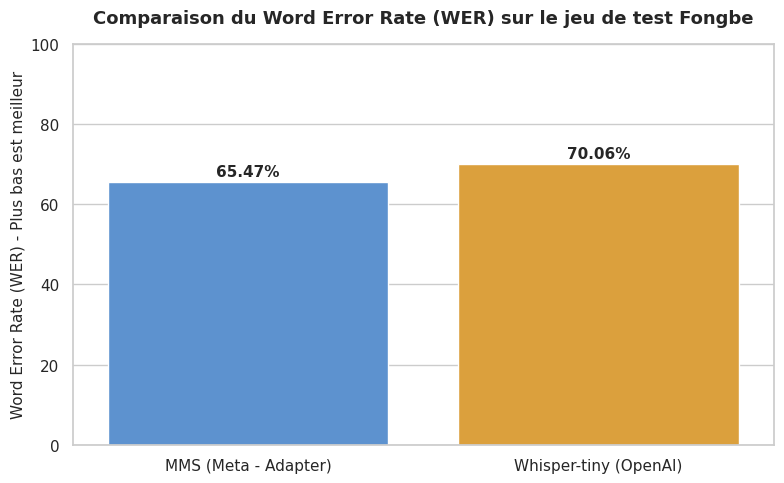

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Définition des performances observées
modeles = ["MMS (Meta - Adapter)", "Whisper-tiny (OpenAI)"]
wer_scores = [65.47, 70.06]

# Configuration de la figure
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Création du diagramme
colors = ["#4A90E2", "#F5A623"]
ax = sns.barplot(x=modeles, y=wer_scores, palette=colors, hue=modeles, legend=False)

# Ajout des valeurs au-dessus des barres
for i, v in enumerate(wer_scores):
    ax.text(i, v + 1.5, f"{v:.2f}%", ha="center", fontweight="bold", fontsize=11)

# Personnalisation des axes et titre
plt.title("Comparaison du Word Error Rate (WER) sur le jeu de test Fongbe", fontsize=13, pad=15, fontweight="bold")
plt.ylabel("Word Error Rate (WER) - Plus bas est meilleur", fontsize=11)
plt.ylim(0, 100)
plt.tight_layout()

# Affichage
plt.show()

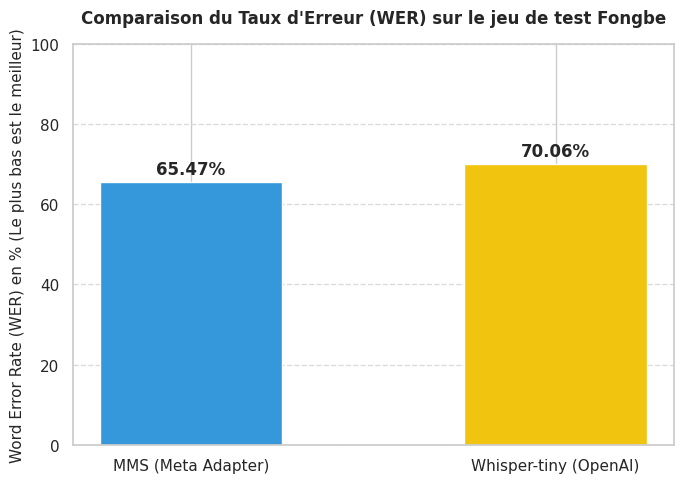

In [ ]:
import matplotlib.pyplot as plt

# Scores de performance (WER)
modeles = ['MMS (Meta Adapter)', 'Whisper-tiny (OpenAI)']
wer_values = [65.47, 70.06]

# Création de la figure
fig, ax = plt.subplots(figsize=(7, 5))

# Tracé des barres
bars = ax.bar(modeles, wer_values, color=['#3498db', '#f1c40f'], width=0.5)

# Ajout des étiquettes de valeur au-dessus des barres
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 points de décalage vertical
                textcoords="offset points",
                ha='center', va='bottom', fontweight='bold')

# Paramètres esthétiques
ax.set_ylim(0, 100)
ax.set_ylabel('Word Error Rate (WER) en % (Le plus bas est le meilleur)', fontsize=11)
ax.set_title('Comparaison du Taux d\'Erreur (WER) sur le jeu de test Fongbe', fontsize=12, fontweight='bold', pad=15)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Étape 1 : Chargement et Test de l'Adapter MMS sauvegardé
Nous allons charger l'adapter du Fongbe (`adapter.fon.safetensors`) ainsi que son processeur associés depuis votre Google Drive afin de réaliser une prédiction de test.

In [ ]:
import os
import torch
from google.colab import drive
from datasets import load_dataset, Audio
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor

# 1. Montage du Google Drive
try:
    drive.mount("/content/drive", force_remount=True)
    dossier_adapter = "/content/drive/MyDrive/adapter-fon"
    print("=> Google Drive connecté.")
except Exception as e:
    print(f"Erreur : {e}")
    dossier_adapter = "./adapter-fon"

# 2. Chargement du processeur sauvegardé
print("Chargement du processeur...")
processor = Wav2Vec2Processor.from_pretrained(dossier_adapter)

# 3. Chargement du modèle de base MMS 1B
print("Chargement du modèle MMS de base...")
model = Wav2Vec2ForCTC.from_pretrained(
    "facebook/mms-1b-all",
    pad_token_id=processor.tokenizer.pad_token_id,
    vocab_size=len(processor.tokenizer),
    ignore_mismatched_sizes=True
)

# 4. Chargement de l'adapter spécifique au Fongbe
print("Application de l'adapter Fongbe...")
model.load_adapter("fon")

# Déplacement sur GPU si disponible
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)
print(f"Modèle MMS prêt sur l'appareil : {device.upper()}")

Mounted at /content/drive
=> Google Drive connecté.
Chargement du processeur...
Chargement du modèle MMS de base...


config.json:   0%|          | 0.00/2.04k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.86GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1096 [00:00<?, ?it/s]

[transformers] Wav2Vec2ForCTC LOAD REPORT from: facebook/mms-1b-all
Key            | Status   |                                                                                            
---------------+----------+--------------------------------------------------------------------------------------------
lm_head.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([154, 1280]) vs model:torch.Size([35, 1280])
lm_head.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([154]) vs model:torch.Size([35])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Application de l'adapter Fongbe...


adapter.fon.safetensors: reconstructing file:   0%|          |  0.00B / 8.89MB            

adapter.fon.safetensors: downloading bytes:           |  0.00B            

Modèle MMS prêt sur l'appareil : CUDA


### Étape 2 : Inférence de test
Nous récupérons un échantillon audio du jeu de test, nettoyons son texte d'origine comme lors de l'entraînement, puis utilisons notre modèle chargé pour transcrire l'audio afin de comparer la prédiction avec la référence.

In [ ]:
import unicodedata
import re

# 1. Chargement d'un exemple du jeu de test
ds_test = load_dataset("Professor/fongbe-speech-zenodo", split="test")
ds_test = ds_test.cast_column("audio", Audio(sampling_rate=16_000))
exemple = ds_test[0]

# 2. Nettoyage de la référence (sans tons comme à l'entraînement)
MAP = {"ε": "ɛ", "ɑ": "a", "ɩ": "i", "\u0306": "\u030c"}
def est_marque(c):
    return unicodedata.category(c).startswith("M")

def nettoyer_texte(texte):
    t = unicodedata.normalize("NFD", texte).lower()
    t = "".join(MAP.get(c, c) for c in t)
    t = "".join(c for c in t if not est_marque(c))
    t = "".join(c if (c.isalnum() or c in " '" or est_marque(c)) else " " for c in t)
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", t)).strip()

reference = nettoyer_texte(exemple["text"])

# 3. Préparation de l'audio et prédiction
inputs = processor(exemple["audio"]["array"], sampling_rate=16_000, return_tensors="pt").to(device)

with torch.no_grad():
    logits = model(inputs.input_values).logits

predicted_ids = torch.argmax(logits, dim=-1)
transcription = processor.batch_decode(predicted_ids)[0]

# 4. Affichage des résultats
print("\n--- RÉSULTAT DU TEST D'INFÉRENCE ---")
print(f"Référence attendue : {reference}")
print(f"Transcription MMS  : {transcription}")